Notebook by Javier Martinez Pinel

# Session 5 - Predictive modelling

Session outcomes:
- Place supervised learning regression inside the wider map of machine learning.
- Introduce the concept of a loss function.
- Derive and implement the closed-form OLS solution.
- Explain overfitting, the bias-variance tradeoff, and how cross-validation is essential.
- Learn how to test a hypothesis using statistical methods.
- Apply all our new knowledge to a trading strategy: Pairs trading


### Index
1. **A map of Machine Learning**  
1.1. Supervised Learning  
1.2. Unsupervised Learning  
1.3. Reinforcement Learning  

2. **Regression task models**  
2.1. Linear regression  

3. **Loss functions**  
3.1. Fitting means minimizing a loss  
3.2. Common loss functions  
3.3. Our loss: squared errors  

4. **Fitting OLS**  

5. **Cross-validation**  
5.1. Why we need to test the model  
5.2. Train/test split  
5.3. k-fold cross-validation  
5.4. Recommended workflow  
5.5. Pitfalls  

6. **Overfitting and regularisation**  
6.1. Overfitting and underfitting  
6.2. Regularisation  

7. **Statistical Testing**  
7.1. Setup: data is noisy  
7.2. The key idea: how surprising is our result?  
7.3. The general procedure  
7.4. A simple example: is the coin fair?  
7.5. How to interpret the result  

8. **Application: Pairs trading**  
8.1. Log-prices and spread  
8.2. Testing cointegration  
8.3. Trading mechanics  
8.4. Where the edge comes from  
8.5. Risks  

## 1. A map of Machine Learning

Machine learning is a branch of artificial intelligence in which computer systems learn patterns from data and use them to make predictions, decisions, or discoveries. It divides into three core categories.

### 1.1. Supervised Learning

The branch of machine learning in which we build mathematical models that predict an outcome (the target) from some input data (the features). The data is labeled: for every datapoint in our training data we know the right answer, and the model learns by comparing its predictions against it. We could later make predictions on datapoints for which we don't know the target. It splits into two types of problems, depending on the kind of target we want to predict.

#### Regression

A supervised problem where the target is a continuous numerical value. The question being answered is "how much?" or "how many?". Examples: the price of a house, tomorrow's temperature, the demand for a product.

#### Classification

A supervised problem where the target is a discrete category. The question being answered is "which one?" or "yes or no?". Examples: whether an email is spam or not, which digit appears in an image, whether a patient has a disease.

### 1.2. Unsupervised Learning

The branch of machine learning in which the data has no labels, and the goal is to discover structure on its own. Instead of making predictions, the model looks for patterns such as groups of similar observations (clustering), simpler representations of the data (dimensionality reduction), or unusual points (anomaly detection). Example: segmenting customers by purchasing behavior without defining the segments beforehand.

### 1.3. Reinforcement Learning

The branch of machine learning in which an agent learns by interacting with an environment. The agent takes actions, receives rewards or penalties, and gradually learns a strategy (a policy) that maximizes its long-term reward. There is no fixed dataset of right answers; learning comes from trial and error. Examples: an agent learning to play chess or Go, or a robot learning to walk.

## 2. Regression models
Regression is one of the two main types of supervised learning, alongside classification. Its goal is to predict a continuous numerical value, like a price or a temperature, from a set of input features. Over the decades, researchers and practitioners have built a huge variety of models to tackle it, like for example:
- Linear regression (classic Ordinary Least Squares (OLS) as well as regularized variants like Ridge and Lasso)
- Neural networks
- Decision trees
- Support Vector Regression

Each one makes different assumptions about the data and trades off simplicity, interpretability, and predictive power in its own way. There is no single best model for every problem, so choosing among them is a big part of the craft. Even so, they all share the same underlying recipe: define a model, choose a loss function, and find the parameters that minimize it.

Below is an example dataset, and we will fit an OLS model.

In [1]:
import seaborn as sns
sns.load_dataset("tips")

df = sns.load_dataset("mpg")
df = df[["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]]
df = df.dropna()   # removes 6 rows with missing horsepower
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70
...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82
394,44.0,4,97.0,52.0,2130,24.6,82
395,32.0,4,135.0,84.0,2295,11.6,82
396,28.0,4,120.0,79.0,2625,18.6,82


### 2.1. Linear Regression (OLS)

#### The model

Linear regression assumes the target is a **linear combination of the features**. For one observation with $n$ features $x₁, …, xₙ$, the model predicts:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n
$$

The model consists of **n + 1 parameters**: one coefficient $βⱼ$ per feature, plus an intercept $β₀$. These numbers are the only things we need to learn from the data. Each coefficient has a direct interpretation: $βⱼ$ is the change in the predicted target when $xⱼ$ increases by one unit, keeping the other features fixed.

In our dataset, the model would look like this:

$$
\widehat{\text{mpg}} = \beta_0 + \beta_1\,\text{cylinders} + \beta_2\,\text{displacement} + \beta_3\,\text{horsepower} + \beta_4\,\text{weight} + \beta_5\,\text{acceleration} + \beta_6\,\text{model\_year}
$$

#### Vector notation
Writing the features as a vector $\mathbf{x} = (x₁, …, xₙ)$ and the coefficients as a vector $\boldsymbol{\beta} = (β₁, …, βₙ)$ lets us express the whole model in a single line: the prediction is the dot product of the two vectors plus an intercept $\beta_0$.

$$
\hat{y} = \boldsymbol{\beta}\cdot\mathbf{x} + \beta_0
$$

This is useful for three reasons. It is compact, since the formula looks the same whether we have 2 features or 2,000, what changes is the shape of the vectors. It is general, because the same expression applies to every observation. And it maps directly onto code and linear algebra, where a dot product is one operation (`X @ beta + alpha`) that the computer can evaluate for the whole dataset at once.

#### Geometric view

With one feature the model can be visualzied as a line in $\mathbb{R}^2$ a **line**, with two features it is a **plane** in $\mathbb{R}^3$, and with $n$ features it is an **$n$-dimensional hyperplane** living in an ($n+1$)-dimensional space ($n$ feature axes plus the target axis). Each observation is a point in that space, and the model is a flat surface passing through the cloud of points.

#### Compact notation

If we add a constant feature $x₀ = 1$, and redefine $\mathbf{x} = (x_0, x₁, …, xₙ) = (1, x₁, …, xₙ)$ then we can redefine $\boldsymbol{\beta} = (\beta_0, β₁, …, βₙ)$ and the prediction is a **dot product**:

$$
\hat{y} = \mathbf{x}\cdot\boldsymbol{\beta} = \mathbf{x}^\top\boldsymbol{\beta}
$$

This way to express the model is, of course, mathematically equivalent to the one above for making predictions. However, their visualizations aren't exactly the same because the vectors in them have one more dimension. This one is slightly more useful for fitting the model, while the other one is more useful for visualization because of its geometric meaning.

If we want to make predictions for a feature dataset at once, we stack the $m$ observations as rows of a matrix $X$ of shape $m × (n+1)$ (first column all ones). We can produce an $m$-dimensional vector of predictions $\hat{\mathbf{y}}$ with simple matrix multiplication:

$$
\hat{\mathbf{y}} = X\boldsymbol{\beta}
$$




In [2]:
import numpy as np
import seaborn as sns

y = df["mpg"].values                                    # shape (392,)
X = np.column_stack([np.ones(len(df)),                  # column of ones for the intercept
                     df.drop(columns="mpg").values])    # shape (392, 7)

## 3. Loss Functions

### 3.1. Fitting means minimizing a loss

In supervised learning, a model has **parameters** (for linear regression, the coefficients $\boldsymbol{\beta}$), and every choice of parameters gives different predictions. To decide which choice is best, we need a way to measure how wrong a model is. That measure is the **loss function**: it takes the model's predictions and the true targets, and returns a single number, where **lower means better**.

Fitting a model is then always the same recipe, whatever the model is:

1. Choose a model with parameters (e.g. a linear model).
2. Choose a loss function that measures the error.
3. Find the parameters that **minimize the loss** on the training data.

Loss functions are present in every supervised model we will ever see, from linear regression to deep neural networks. The model changes, the loss changes, but the idea stays the same.

### 3.2. Common loss functions

Different problems call for different losses:

| Problem | Typical loss |
|---|---|
| Regression | Sum of quared error, sum of absolute error |
| Classification | Cross-entropy (log loss) |

### 3.3. Our loss: squared errors

In our example, the loss is the **squared error**. For each observation in our training data, the **residual** is the difference between the true value and the prediction:

$$
r_i = y_i - \hat{y}_i = y_i - (\boldsymbol{\beta}\cdot\mathbf{x}_i + \alpha)
$$

The loss adds up the squared residuals over all m observations:

$$
L(\boldsymbol{\beta}, \alpha) = \sum_{i=1}^{m} \left(y_i - \hat{y}_i\right)^2 = \sum_{i=1}^{m} \left(y_i - \boldsymbol{\beta}\cdot\mathbf{x}_i - \alpha\right)^2
$$

This is the loss that gives **Ordinary Least Squares (OLS)** its name. The best model is the one with the smallest sum of squared residuals.

In [3]:
def squared_error_loss(beta, alpha, X, y):
    y_hat = X @ beta + alpha
    return np.sum((y - y_hat) ** 2)

#### Why squared?

* **Errors can't cancel out.** If we simply added the residuals, a positive error and a negative error would offset each other, and a terrible model could score well.
* **Large errors are punished more.** A single error of 10 costs 100, while ten errors of 1 cost only 10, so the model works hard to avoid big misses.
* **It is smooth.** The loss is differentiable everywhere, which makes it easy to minimize (it even has a closed-form solution, as we will see next).

The price of squaring is sensitivity to **outliers**: one extreme point can pull the fitted line a long way. An alternative is the absolute error, $\sum |r_i|$, which is more robust but harder to minimize.

#### Visualizing it

Each observation contributes one vertical segment between the point and the line. The loss is the sum of the squares of these segment lengths. Different choices of $\boldsymbol{\beta}$ tilt and shift the line, making the segments longer or shorter, and OLS picks the choice that makes the total smallest.

The line with the lower loss fits the data better. Fitting the model is the process of finding the line with the lowest loss of all.

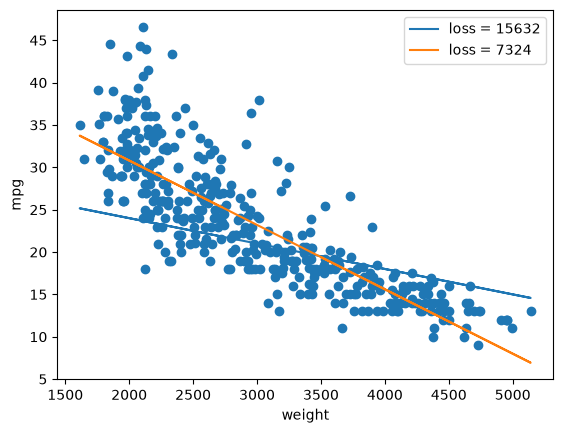

In [4]:
import matplotlib.pyplot as plt

x = df["weight"].values
plt.scatter(x, y)
for beta1, alpha in [(-0.003, 30), (-0.0076, 46)]:       # two candidate lines
    plt.plot(x, beta1 * x + alpha,
             label=f"loss = {squared_error_loss(np.array([beta1]), alpha, x.reshape(-1, 1), y):.0f}")
plt.xlabel("weight"); plt.ylabel("mpg"); plt.legend(); plt.show()

## 4. Fitting OLS

Because the loss function is a quadratic function of $\boldsymbol{\beta}$, we can minimize it exactly, without searching. We can do it with the usual method of differentiating and setting equalt to 0. However, some of you might only be used to a derivative with respect to a single variable, not to an entire vector. For that, we must introduce the concept of a gradient.

The **gradient** of a multivariable function $f(x_1, ..., x_n)$ (just like the loss function), written as $\nabla f$, is simply a vector that collects the derivatives of $f$ with respect to each parameter: its $j^{th}$ entry is $\frac{\partial f}{\partial x_j}$, which tells us how the loss changes if we nudge $x_j$ while keeping the others fixed. To compute it in the specific case of our loss function, where we view it as a multivariable function $L(\beta_0, ..., \beta_n)$, start with the squared error of a **single** datapoint $i$:

$$
\frac{\partial}{\partial \beta_j}\left(y_i - \mathbf{x}_i\cdot\boldsymbol{\beta}\right)^2 = 2\left(y_i - \mathbf{x}_i\cdot\boldsymbol{\beta}\right)\cdot(-x_{ij}) = -2\,x_{ij}\left(y_i - \mathbf{x}_i\cdot\boldsymbol{\beta}\right)
$$

Here, we have labeled $\mathbf{x}_i$ as the $i$-th row of $X$, corresponding with the $i$-th datapoint. $x_{ij}$ would then be the entry in the $i$-th row and $j$-th column of $X$, or equivalently the $j$-th entry of $\mathbf{x}_i$. We used the chain rule: the derivative of the square is 2 times the inside, times the derivative of the inside. Since the total loss is the sum of the errors of all datapoints, and differentiation is linear, we can add up these contributions to get $\frac{\partial L}{\partial \beta_j}$:

$$
\frac{\partial L}{\partial \beta_j} = \sum_{i=1}^{m} -2\,x_{ij}\left(y_i - \mathbf{x}_i\cdot\boldsymbol{\beta}\right) = -2\,\mathbf{x}^{(j)}\cdot(\mathbf{y} - X\boldsymbol{\beta})
$$

where $\mathbf{x}^{(j)}$ is the $j$-th *column* of $X$ (the values of feature $j$ across all datapoints). This sum is exactly the $j$-th entry of the vector $-2X^\top(\mathbf{y} - X\boldsymbol{\beta})$, because the $j$-th row of $X^\top$ is that column. Stacking the derivatives for $j = 1, \dots, n$ gives the full gradient:

$$
\nabla_{\boldsymbol{\beta}} L = -2X^\top(\mathbf{y} - X\boldsymbol{\beta})
$$

*(Note: here the index $j$ runs over parameters and $i$ over datapoints, to avoid mixing the two.)*

We take the gradient with respect to $\boldsymbol{\beta}$ and set it to zero:

$$
\nabla_{\boldsymbol{\beta}} L = -2X^\top\left(\mathbf{y} - X\boldsymbol{\beta}\right) = 0
$$

Rearranging gives the **normal equations**:

$$
X^\top X\,\boldsymbol{\beta} = X^\top\mathbf{y}
$$

and, when $X^\top X$ is invertible, the solution:

$$
\boxed{\hat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}}
$$

This is a global minimum, because the loss is a convex "bowl" in $\boldsymbol{\beta}$-space: there are no local minima to get stuck in.

### Implementation


In [5]:
# Closed-form solution (solving the normal equations is more stable than inverting)
beta_hat = np.linalg.solve(X.T @ X, X.T @ y)
print(beta_hat)

# Predictions and residuals
y_hat = X @ beta_hat
residuals = y - y_hat
print("Sum of squared residuals:", np.sum(residuals**2))

[-1.45352505e+01 -3.29859089e-01  7.67843024e-03 -3.91355574e-04
 -6.79461791e-03  8.52732469e-02  7.53367180e-01]
Sum of squared residuals: 4543.347024714767


### When the closed form fails

* **Perfect collinearity:** if one feature is an exact linear combination of others, $X^\top X$ is not invertible and there is no unique solution.
* **Near collinearity:** the solution exists but the coefficients become unstable, with large values and large variance. This is a real concern in this dataset, since displacement, cylinders, horsepower and weight are strongly correlated.
* **Too few observations:** we need at least $n + 1$ rows to determine $n + 1$ parameters.
* **Very large $n$:** inverting $X^\top X$ costs about $O(n^3)$, so for huge feature sets we use iterative methods like gradient descent instead.

## 5. Cross-Validation
Cross-validation is a technique for estimating how well a model will perform on unseen data, by splitting the dataset into training and test parts, fitting the model on the training part and evaluating it on the held-out part.

### 5.1. Why we need to test the model

A model is only useful if it predicts well on **new data**, meaning data it has never seen. The loss on the training data cannot tell us that. When we add features to an OLS model, the training loss can only go down or stay the same, even if the new features are pure noise. So "lowest training error" simply rewards the most flexible model, and a model that memorizes the training set would look perfect while being useless in practice.

The only honest way to measure performance on unseen data is to **actually hold some data out**, fit the model without it, and evaluate on it. This works for any model, with no assumptions about the data, and that is why cross-validation is the standard tool for judging a model.

### 5.2. Train/test split

The simplest version of cross-validation splits the data into two parts:

* **Training set** (e.g. 80%): used to fit the parameters $\boldsymbol{\beta}$.
* **Test set** (e.g. 20%): never used for fitting, only to measure the error afterwards.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = df.drop(columns="mpg")   # feature matrix
y = df["mpg"]                # target vector

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LinearRegression().fit(X_train, y_train)
print("Train MSE:", mean_squared_error(y_train, model.predict(X_train)))
print("Test  MSE:", mean_squared_error(y_test,  model.predict(X_test)))

Train MSE: 11.546404006864584
Test  MSE: 11.878262288865697


Here we report the **mean squared error** (MSE), which is the loss divided by the number of datapoints, so that it doesn't grow with the size of the dataset. If the test error is much larger than the training error, the model does not generalize.

A single split has two problems. The result depends on which rows happened to end up in the test set, which matters a lot on small datasets like ours. And if we use the test error to make choices (which features to keep, which model to use), we are indirectly fitting to the test set, so it stops being "unseen".

### 5.3. k-fold cross-validation

k-fold cross-validation fixes the first problem by repeating the split several times so that every datapoint is used for testing exactly once:

1. Split the data into $k$ equally sized **folds** (typically $k = 5$ or $k = 10$).
2. For each fold $i = 1, \dots, k$: fit the model on the other $k-1$ folds and compute the error on fold $i$.
3. Average the $k$ errors:

$$
\text{CV}_k = \frac{1}{k}\sum_{i=1}^{k} \text{MSE}_i
$$

```
Fold 1: [TEST ][train][train][train][train]
Fold 2: [train][TEST ][train][train][train]
Fold 3: [train][train][TEST ][train][train]
Fold 4: [train][train][train][TEST ][train]
Fold 5: [train][train][train][train][TEST ]
```

In [7]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="neg_mean_squared_error")

print("MSE per fold:", -scores)
print(f"CV MSE: {-scores.mean():.2f} (+/- {scores.std():.2f})")

MSE per fold: [11.87826229 10.46916623 14.91985103 13.36094788 10.5050927 ]
CV MSE: 12.23 (+/- 1.72)


(scikit-learn reports the *negative* MSE because its convention is that higher scores are better.) The spread across folds also tells us how stable the estimate is.

### 5.4. Recommended workflow

1. Set aside a final **test set** and do not touch it.
2. Use cross-validation on the remaining data to compare models and choose their settings.
3. Refit the chosen model on all the non-test data.
4. Evaluate it **once** on the final test set.

### 5.5. Pitfalls

* **Data leakage:** any preprocessing that learns from the data (scaling, imputing missing values, selecting features) must be fitted *inside* each training fold, not on the whole dataset. In scikit-learn, use a `Pipeline` for this.
* **Time series:** If the data was a time series (each different observation correspoinds to a different point in time in a relevant way), do not shuffle. Always train on the past and test on the future.

## 6. Overfitting and Regularisation

### 6.1. Overfitting and underfitting

A model **overfits** when it learns the noise in the training data instead of the underlying pattern. Its training error is very low, but its error on new data is high. The opposite problem is **underfitting**: the model is too simple to capture the pattern, so the error is high on both training and new data.

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| Model is | too simple | just right | too flexible |
| Training error | high | low | very low |
| Error on new data | high | low | high |

Linear regression is not immune to this. We can make it more flexible by adding more features, for example powers of a variable ($x$, $x^2$, $x^3$, ...), which is still linear in the parameters. The demo below fits polynomials of increasing degree to $\text{mpg}$ as a function of $\text{weight}$:


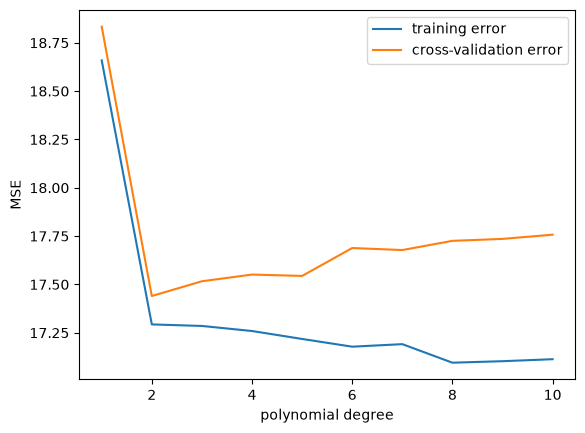

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt

Xw = df[["weight"]]
degrees = range(1, 11)
train_err, cv_err = [], []

for d in degrees:
    pipe = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    res = cross_validate(pipe, Xw, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    train_err.append(-res["train_score"].mean())
    cv_err.append(-res["test_score"].mean())

plt.plot(degrees, train_err, label="training error")
plt.plot(degrees, cv_err, label="cross-validation error")
plt.xlabel("polynomial degree"); plt.ylabel("MSE"); plt.legend(); plt.show()

The training error keeps decreasing as the degree grows, while the cross-validation error stops improving and eventually rises. That is overfitting made visible, and it is why we choose models by their cross-validation error.

#### Why it happens: bias and variance

The error on new data has two main sources. **Bias** is the error from a model that is too simple to represent the truth. **Variance** is the error from a model so flexible that its fitted parameters change a lot depending on the particular training sample. A more flexible model has lower bias but higher variance, and the best model balances the two.

### 6.2. Regularisation

**Regularisation** reduces overfitting by changing the loss function. Instead of only measuring the error, we also **penalize large coefficients**:

$$
L_{\text{regularised}}(\boldsymbol{\beta}) = \underbrace{\sum_{i=1}^{m}\left(y_i - \hat{y}_i\right)^2}_{\text{squared error}} + \lambda \cdot \underbrace{\text{Penalty}(\boldsymbol{\beta})}_{\text{size of coefficients}}
$$

The number $\lambda \geq 0$ controls the trade-off. With $\lambda = 0$ we recover plain OLS, and as $\lambda$ grows, the coefficients are pushed towards zero. A simpler, "smaller" model has less variance, at the cost of a little bias. The intercept is normally not penalized.

The two most famous choices of penalty give two models, both still **linear regression** (same hyperplane model, different loss):

**Ridge regression** penalizes the sum of squared coefficients:

$$
L_{\text{ridge}}(\boldsymbol{\beta}) = \sum_{i=1}^{m}\left(y_i - \hat{y}_i\right)^2 + \lambda \sum_{j=1}^{n}\beta_j^2
$$

It still has a closed-form solution, and it comes with a bonus: $X^\top X + \lambda I$ is always invertible for $\lambda > 0$, so Ridge fixes the collinearity problem of OLS.

$$
\hat{\boldsymbol{\beta}}_{\text{ridge}} = (X^\top X + \lambda I)^{-1} X^\top \mathbf{y}
$$

**Lasso regression** penalizes the sum of absolute values of the coefficients:

$$
L_{\text{lasso}}(\boldsymbol{\beta}) = \sum_{i=1}^{m}\left(y_i - \hat{y}_i\right)^2 + \lambda \sum_{j=1}^{n}|\beta_j|
$$

It has no closed-form solution and is fitted with iterative algorithms, but it can set some coefficients **exactly to zero**, so it also performs feature selection.

| | OLS | Ridge | Lasso |
|---|---|---|---|
| Penalty | none | $\lambda\sum\beta_j^2$ | $\lambda\sum\lvert\beta_j\rvert$ |
| Closed form | yes | yes | no |
| Coefficients | unrestricted | shrunk towards zero | shrunk, some exactly zero |
| Handles collinearity | poorly | well | picks one among correlated features |

#### Practical details

* **Standardize the features first.** The penalty treats all coefficients equally, but a coefficient's size depends on the units of its feature (weight in kilograms or in grams, for example). Scaling each feature to mean 0 and standard deviation 1 puts them on equal footing.
* **Choose $\lambda$ with cross-validation.** It is not a parameter learned from the loss, so we try several values and keep the one with the lowest CV error.
* **Naming clash:** scikit-learn calls the penalty strength `alpha`, which is our $\lambda$.

In [9]:
import numpy as np
from sklearn.linear_model import RidgeCV, LassoCV

ols   = make_pipeline(StandardScaler(), LinearRegression())
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5))
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5))

for name, m in [("OLS", ols), ("Ridge", ridge), ("Lasso", lasso)]:
    scores = cross_val_score(m, X, y, cv=cv, scoring="neg_mean_squared_error")
    print(f"{name}: CV MSE = {-scores.mean():.2f}")

# Compare the coefficients
for name, m in [("OLS", ols), ("Ridge", ridge), ("Lasso", lasso)]:
    m.fit(X, y)
    print(name, m[-1].coef_.round(2))

OLS: CV MSE = 12.23
Ridge: CV MSE = 12.23
Lasso: CV MSE = 12.15
OLS [-0.56  0.8  -0.02 -5.76  0.23  2.77]
Ridge [-0.56  0.8  -0.02 -5.76  0.23  2.77]
Lasso [-0.17 -0.   -0.   -5.38  0.11  2.69]


Look at the coefficients of the correlated features (displacement, cylinders, horsepower, weight): OLS may give large values with mixed signs, Ridge shrinks them and spreads the weight among them, and Lasso may set some of them exactly to zero.

## 7. Statistical Testing

### 7.1. Setup: data is noisy

Very often we have a dataset and want to answer a question about the **process that generated it**. Is this coin fair? Is a regression coefficient really different from zero, or does it just look that way? Each of these is a claim about the **underlying distribution** of the data, which we cannot observe directly. All we have is one finite sample drawn from it.

This is the difficulty. A sample is random: if we repeated the experiment we would get a different dataset, with different numbers, even if nothing about the underlying process had changed. So a dataset can *look* like it supports a claim purely by chance. Flip a fair coin 10 times and you will sometimes get 7 heads, which does not mean the coin is biased. We need a way to tell apart "the data differs from what the claim predicts because the claim is false" from "the data differs because of random fluctuations".

### 7.2. The key idea: how surprising is our data?

The approach is to take the claim we want to challenge, called the **null hypothesis** $H_0$, which fully specifies the process that generated the data, and **assume it is true**. Under that assumption, we can ask:

> If $H_0$ were true, how likely would it be to get a dataset **as extreme as, or more extreme than**, the one we actually got?

That probability is called the **p-value**. If it is large, our data is perfectly ordinary under $H_0$, and we have no reason to doubt it. If it is very small, then either we were extraordinarily unlucky, or $H_0$ is false. When the p-value is small enough, we conclude the second option is more plausible and **reject** $H_0$.

The logic is a probabilistic version of proof by contradiction: assume $H_0$, see whether the data is compatible with it, and reject it if the data would be too improbable.

### 7.3. The general procedure

**1. State the hypotheses.** The **null hypothesis** $H_0$ is the "nothing interesting is happening" claim, stated precisely enough to compute probabilities from it (e.g. "the coin is fair", "$\gamma = 0$"). The **alternative hypothesis** $H_1$ is what we would conclude if we reject $H_0$ (e.g. "the coin is biased", "$\gamma < 0$").

**2. Choose a test statistic.** A raw dataset has too many numbers to compare against anything, so we compress it into a single number $T(\text{data})$ called the **test statistic**. It should be chosen so that more extreme values mean stronger evidence against $H_0$. Typical examples are a count, a difference of means, or an estimate divided by its standard error (a **t-statistic**), which measures how many standard errors the estimate lies from the value $H_0$ predicts.

**3. Find the distribution of the statistic under $H_0$.** Because the data is random, $T$ is a random variable. Assuming $H_0$ is true, it follows a known distribution, which we call **null distribution**. Finding this distribution might be a challenge in some cases. Sometimes it comes from a formula, and sometimes it has no closed form and is obtained by **simulation**: generate many datasets in which $H_0$ holds, compute $T$ for each, and look at the resulting histogram.

**4. Compute the observed statistic.** Evaluate the test statistic on our real data, obtaining a number $t_{\text{obs}}$.

**5. Compute the p-value.** The p-value is the probability, under the null distribution, of a statistic at least as extreme as $t_{\text{obs}}$. What counts as "extreme" depends on the $H_1$ of our particular case:

$$
p = P\left(T \geq t_{\text{obs}} \mid H_0\right) \quad \text{(large values are extreme)}
$$

$$
p = P\left(T \leq t_{\text{obs}} \mid H_0\right) \quad \text{(small values are extreme)}
$$

$$
p = P\left(|T| \geq |t_{\text{obs}}| \mid H_0\right) \quad \text{(deviations in either direction are extreme)}
$$

The first two are **one-sided** tests and the last is **two-sided**. Which one applies is decided by the question, *before* looking at the data.

**6. Make a decision.** We fix a **significance level** $\alpha$ in advance (commonly $0.05$). If $p < \alpha$, we **reject** $H_0$. Otherwise we **fail to reject** it. The level $\alpha$ is the probability of wrongly rejecting a true $H_0$ that we are willing to accept (a **false positive**). Picking it after seeing the data would defeat the purpose.

### 7.4. A simple example: is the coin fair?

We flip a coin $n = 100$ times and get $60$ heads. If I asked you what the probability of heads for this coin was, what would you do? You might be tempted to calibrate this probability with the data provided, which would give you a probability of $\frac{3}{5}$. This is a common pitfall, since, even if the coin might truly be biased, in the world we live in they are typically fair. So it would be pertinent to ask the question: Is the coin biased? We will answer it with a statistical test.

1. $H_0$: the coin is fair ($P(\text{heads}) = 0.5$). $H_1$: it is not.
2. Test statistic: the number of heads $T$.
3. Under $H_0$, $T$ follows a $\text{Binomial}(100, 0.5)$ distribution, centered at $50$.
4. Observed: $t_{\text{obs}} = 60$.
5. Deviations in either direction are evidence of bias, so the test is two-sided: we want the probability of being at least $10$ away from $50$, i.e. $T \geq 60$ or $T \leq 40$. This gives $p \approx 0.057$.
6. With $\alpha = 0.05$, $p > \alpha$, so we **fail to reject** $H_0$.

Even though 60 heads *feels* like a lot, a fair coin produces a result this far from 50 about 6% of the time. We don't have enough evidence to call the coin biased.

In [10]:
import numpy as np
from scipy.stats import binomtest

n, observed = 100, 60

# Exact p-value from the binomial distribution
print(binomtest(observed, n, p=0.5).pvalue)            # ≈ 0.057

# The same thing by simulation: build the null distribution ourselves
rng = np.random.default_rng(0)
sims = rng.binomial(n, 0.5, size=200_000)               # 200k experiments with a fair coin
p_sim = np.mean(np.abs(sims - 50) >= abs(observed - 50))
print(p_sim)  

0.05688793364098079
0.056665


The simulation shows what the p-value means in practice: it is the fraction of fair-coin experiments that look at least as extreme as ours.

### 7.5. How to interpret the result

* **A small p-value** means the data would be unlikely if $H_0$ were true. It is evidence against $H_0$, but it is not proof.
* **A large p-value does not prove $H_0$ is true.** It only says the data is compatible with it. We "fail to reject", we never "accept". With little data, even a real effect can produce a large p-value (a false negative, or type II error).
* **The p-value is not the probability that $H_0$ is true.** It is the probability of data like ours *given* $H_0$, which is a different quantity: $P(\text{data} \mid H_0) \neq P(H_0 \mid \text{data})$.
* **Statistically significant does not mean important.** With enough data, tiny and practically irrelevant effects get very small p-values. The size of the effect still has to be judged separately.
* **Testing many hypotheses inflates false positives.** If we run 100 tests at $\alpha = 0.05$, we expect about 5 rejections even when every $H_0$ is true. This is why we decide the tests in advance, and why scanning many candidates for a small p-value is dangerous.

### Summary

| Step | Question it answers |
|---|---|
| Hypotheses | What exactly are we claiming, and what is the alternative? |
| Test statistic | How do we compress the data into one number to measure its extremeness? |
| Null distribution | How would that number behave if $H_0$ were true? |
| Observed statistic | What did our data give? |
| p-value | How surprising is that, if $H_0$ were true? |
| Decision | Is it surprising enough (below $\alpha$) to reject $H_0$? |

## 8. Application: Pairs trading

Some pairs of stocks, such as Coca-Cola (KO) and Pepsi (PEP), are driven by the same forces. Each wanders unpredictably, but if the pair is **cointegrated**, the *gap* between them stays bounded and keeps returning to a mean. Pairs trading is only performed on pairs that pass this property, so before trading we **test for cointegration** on historical data and discard any pair that fails. For the pairs that pass, when the gap stretches we bet it snaps back, holding positions that cancel the common market moves. The profit comes from the gap closing, not from the direction of either stock.

### 8.1. Log prices and spread

Let $P^{KO}_t$ and $P^{PEP}_t$ be the prices at time $t$, and define

$$x_t = \ln P^{KO}_t, \qquad y_t = \ln P^{PEP}_t.$$

Each follows roughly a GBM (as in Session 2), so each is **non-stationary**: it has no long-run level to return to.

Over a formation window of $T$ daily observations, regress one log price on the other:

$$y_t = \alpha + \beta x_t + \varepsilon_t.$$

- $\alpha$: intercept (a constant offset between the two)
- $\beta$: (called the **hedge ratio**) the dollars of KO that offset one dollar of PEP
- $\varepsilon_t$: the part of PEP not explained by KO

In other words, we are going to make an OLS linear regression model to predict $y$ with $x$:

$$\hat{y} = \alpha + \beta x$$

Fit parameters $\alpha$ and $\beta$ my minimiing the sum of squared errors $y_t - \hat{y}_t$. The closed form solution of ordinary least squares gives

$$\hat\beta = \frac{\operatorname{Cov}(x,y)}{\operatorname{Var}(x)}, \qquad \hat\alpha = \bar y - \hat\beta \bar x.$$

We define the **spread** as the the fitted residual:

$$s_t = y_t - \hat\alpha - \hat\beta x_t.$$

Because log-price changes approximate percentage changes, $s_t$ is roughly the percentage by which PEP is rich (positive) or cheap (negative) relative to KO.

The code below implements this with code.

In [11]:
# %%
import numpy as np
import pandas as pd
import yfinance as yf

# Formation window: the data we use to estimate the hedge ratio and test cointegration
X_TICKER, Y_TICKER = "KO", "PEP"            # regress PEP (y) on KO (x)
START, END = "2015-01-01", "2020-01-01"     # yfinance's end date is exclusive

# Download adjusted closing prices and keep the days where both stocks have data
raw = yf.download([X_TICKER, Y_TICKER], start=START, end=END,
                  auto_adjust=True, progress=False)["Close"]
prices = raw[[X_TICKER, Y_TICKER]].dropna()

# Log prices as plain numpy arrays
x = np.log(prices[X_TICKER].to_numpy())     # shape (T,)
y = np.log(prices[Y_TICKER].to_numpy())     # shape (T,)

# OLS fit of y_t = alpha + beta * x_t + eps_t (closed form for one feature)
beta = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
alpha = y.mean() - beta * x.mean()

# Spread: the residuals of the fit
s = y - alpha - beta * x                    # shape (T,)

print(f"Observations: {len(s)}")
print(f"alpha = {alpha:.4f}, beta = {beta:.4f}")
print(f"Spread: mean = {s.mean():.2e}, std = {s.std(ddof=1):.4f}")

Observations: 1258
alpha = 0.5450, beta = 1.0985
Spread: mean = -2.49e-16, std = 0.0428


### 8.2. Testing cointegration

Correlation of returns does not guarantee the gap returns to a level: two stocks can have $\rho = 0.9$ and still drift apart forever. What we need is **cointegration**: $x_t$ and $y_t$ are each non-stationary, but the combination $s_t$ is **stationary** (it keeps returning to a mean).

We test it with the **Engle-Granger procedure**: fit the regression above, then run an **augmented Dickey-Fuller (ADF) test** on $s_t$.

#### Testing cointegration: Dickey-Fuller test

The **Dickey-Fuller (DF) test** is a statistical test (just like what we describe in section 7) that checks whether a time series is a **random walk** (non-stationary) or **mean-reverting** (stationary). In pairs trading, this is exactly the question we need to answer about the spread $s_t$: does it keep returning to a level, or can it wander away forever?

To see the idea, model a series as

$$s_t = \phi\, s_{t-1} + u_t,$$

where $u_t$ is random noise.

- If $|\phi| < 1$, large values tend to be followed by smaller ones: the series is pulled back towards its mean. It is **stationary**.
- If $\phi = 1$, there is no pull: $s_t = s_{t-1} + u_t$ is a random walk.

Subtracting $s_{t-1}$ from both sides gives the form the test actually uses:

$$\Delta s_t = \gamma\, s_{t-1} + u_t, \qquad \Delta s_t = s_t - s_{t-1}, \qquad \gamma = \phi - 1.$$

This is, again, a linear regression where the target is the change $\Delta s_t$ and the feature is the previous level $s_{t-1}$. We now have two hypothesis:

- **Null hypothesis** $H_0$: $\gamma = 0$ (unit root, no mean reversion).
- **Alternative** $H_1$: $\gamma < 0$ (stationary, mean-reverting). A positive $s_{t-1}$ then predicts a negative change, which is the "snap back" we want to trade.

We will then perform a statistical test on our $H_0$, to see whether it is statistically safe to reject it. The first step now would be to choose a test statistic to measure how extreme the data in our series $s_t$ if we assume $\gamma = 0$. We do that the following way:

#### The Dickey-Fuller statistic and its p-value

We estimate $\gamma$ by OLS, regressing the changes $\Delta s_t$ on the previous levels $s_{t-1}$. This linear regression has no intercept, because the spread already has mean zero by construction ($s_t$ are the residuals of an OLS fit that includes an intercept, and those always average to zero). With a single feature and no intercept, the closed form is

$$\hat\gamma = \frac{\sum_t s_{t-1}\,\Delta s_t}{\sum_t s_{t-1}^2}.$$

The **Dickey-Fuller statistic** (or DF statistic) is the estimate, $\hat\gamma$, divided by its **standard error** (SE), which measures how much $\hat\gamma$ would vary from sample to sample due to noise. This number gives us how many standard errors our estimate lies from the value $H_0$ predicts. Therefore, this is the test-statistic we are going to use to determine whether we can reject $H_0$.

$$\text{DF} = \frac{\hat\gamma}{\operatorname{SE}(\hat\gamma)}, \qquad \operatorname{SE}(\hat\gamma) = \frac{\hat\sigma}{\sqrt{\sum_t s_{t-1}^2}}, \qquad \hat\sigma^2 = \frac{1}{N-1}\sum_t \left(\Delta s_t - \hat\gamma\, s_{t-1}\right)^2,$$

where $N$ is the number of observations in the regression and $\hat\sigma^2$ is the estimated variance of the noise $u_t$. In words, DF tells us how many standard errors $\hat\gamma$ lies away from zero, the value it would have under $H_0$.

A very negative value is evidence for mean reversion. Now, remember that if $H_0$ is true, then $s_t$ is a random walk, but different simulations of the same random walk would give a different $\text{DF}$. The distribution of this $\text{DF}$ is what we use to turn it into our p-value. The problem is the distribution of $\text{DF}$ under $H_0$ has no closed form, and was obtained by **simulation**: generate many random walks, compute the statistic for each, and look at the resulting distribution. It is shifted to the left of a normal one, so the critical values are stricter. For example, with a constant the 5% critical value is about $-2.86$, compared with $-1.65$ for a one-sided normal test. The p-value is the fraction of simulated statistics at or below the one we observed. In practice, software reads it from tables fitted to these simulations.

**Augmented version (ADF).** The basic test assumes the noise $u_t$ is uncorrelated over time, which is rarely true with real data. The augmented test adds lagged differences to absorb that autocorrelation:

$$\Delta s_t = \gamma\, s_{t-1} + \delta_1 \Delta s_{t-1} + \dots + \delta_p \Delta s_{t-p} + u_t.$$

The null hypothesis is still $\gamma = 0$, and the number of lags $p$ is usually chosen automatically (e.g. by minimizing AIC).

#### Applying it to our pair

In the previous code cell we regressed $y_t$ with $x_t$ as an indicator and calculated the spread $s_t$. In the following code cell, we apply the augmented Dickey-Fuller test to $s_t$ to determine whether it's a random walk or it's stationary (mean-reverting). After implementing the test, we will get some p-value:

- **Small p-value** (e.g. below $0.05$): we reject the null-hypothesis (that it's a random walk). The spread looks stationary, so the pair is cointegrated and is a candidate for trading.
- **Large p-value:** we cannot reject the random walk. The gap may drift away forever, so we discard the pair.

Note that not rejecting $H_0$ is not proof that the pair is *not* cointegrated, only that we lack evidence. Since the whole strategy relies on mean reversion, we are conservative and trade only the pairs that pass.

**A subtlety.** The spread is built using the *estimated* $\hat\beta$, which was chosen precisely to make the residuals as small and stable as possible. This makes $s_t$ look more stationary than it really is, so the standard DF critical values are too lenient. The correct test uses adjusted critical values (MacKinnon's), which are stricter: about $-3.34$ at the 5% level for a pair with a constant. This is why, in code, we use the dedicated cointegration test and not a plain ADF on the residuals, like below:8

In [12]:
import numpy as np
from statsmodels.tsa.stattools import coint

# x, y: arrays of log prices of KO and PEP over the formation window
stat, pvalue, crit_values = coint(y, x)    # Engle-Granger with adjusted critical values

print(f"statistic: {stat:.2f}, p-value: {pvalue:.3f}")
print("critical values (1%, 5%, 10%):", crit_values)

if pvalue < 0.05:
    print("Reject the unit root: the spread looks mean-reverting. Keep the pair.")
else:
    print("Cannot reject a random walk: discard the pair.")

statistic: -3.16, p-value: 0.076
critical values (1%, 5%, 10%): [-3.90517395 -3.34099518 -3.04782579]
Cannot reject a random walk: discard the pair.


Under the hood, this fits the regression above, computes the spread, runs an ADF test on it, and compares the statistic with the Engle-Granger critical values. And, as you can see, it is much simpler for us than coding the whole test ourselves.

### 8.3. Trading mechanics

Once we determine whether our two stocks are suitable for pairs trading because they are cointegrated, the next step is to come up with the trading mechanics. When do we trade? When do we cancel our positions and collect earnings? When do we pull out because the pattern might've broken? We do that the following way:

#### Mean-reversion model: Ornstein-Uhlenbeck

We model the spread as an OU process:

$$ds_t = \theta(\mu - s_t)\,dt + \sigma\,dW_t$$

- $\mu$: long-run mean the spread is pulled toward
- $\theta > 0$: speed of reversion (the stiffness of the spring)
- $\sigma$: volatility of the random kicks
- $W_t$: Brownian motion

Compare with the GBM from Session 2: a GBM has a drift but no anchor, while an OU process has an anchor $\mu$.

**Calibration.** Discretise with step $\Delta t$ and regress the spread on its own lag:

$$s_{t+1} = a + b\,s_t + \eta_t.$$

Then

$$b = e^{-\theta \Delta t} \implies \theta = -\frac{\ln b}{\Delta t}, \qquad \mu = \frac{a}{1-b}, $$

and the standard deviation of the residuals $\eta_t$ gives $\sigma$ through $\sigma_\eta^2 = \sigma^2\,\dfrac{1-b^2}{2\theta}$. We need $0 < b < 1$: if $b \ge 1$ there is no mean reversion and nothing to trade.

These mathematical relations between the quantities $a$ and $b$, which we can easily calibrate with data, and the parameters $\mu$, $\theta$ and $\sigma$ are derived using stockastic calculus. In particular, using Ito's Lemma, which we briefly talked about in session 2. Unfortunately, we will not specify the details of how they are derived, but it is proven work by other mathematicians, so you're just gonna have to take their word for it to keep moving forward.

#### Derived quantities

- **Half-life:** the typical time for a deviation to halve,
$$t_{1/2} = \frac{\ln 2}{\theta}.$$
It tells us the expected holding period and filters out pairs that revert too slowly (capital tied up) or too fast (costs dominate).
- **Equilibrium standard deviation:** the typical size of deviations around $\mu$,
$$\sigma_{eq} = \frac{\sigma}{\sqrt{2\theta}}.$$
- **Z-score:** the trading signal,
$$z_t = \frac{s_t - \mu}{\sigma_{eq}}.$$

Since OLS forces the in-sample residuals to average zero, $\hat\mu \approx 0$ on the formation window.

#### Trading rules (illustrative thresholds)

| Condition | Meaning | Trade |
|---|---|---|
| $z_t > +2$ | PEP rich relative to KO | Short PEP, long KO |
| $z_t < -2$ | PEP cheap relative to KO | Long PEP, short KO |
| $\lvert z_t \rvert < 0.5$ | Spread back near normal | Close both legs |
| $\lvert z_t \rvert > 3.5$ | Relationship may have broken | Stop-loss |
| Time $> 2$-$3\,t_{1/2}$ | Not reverting | Close both legs |

**Sizing.** For $N$ dollars of PEP, hold $\beta N$ dollars of KO on the opposite side. The position is then hedge-ratio neutral, so common moves in the two stocks largely cancel.

**Upkeep.** Each day, update prices, re-estimate $\beta$, $\mu$, $\sigma_{eq}$ on a rolling window, recompute $z_t$, and adjust or close positions.

#### Numerical example (illustrative numbers)

Suppose the estimates are $\hat\beta = 0.8$, $\hat\mu = 0$, $\sigma_{eq} = 2\%$, and a half-life of about 10 days.

1. **Entry:** the spread is $s_t = 4.6\%$, so $z_t = 4.6/2 = 2.3 > 2$. PEP looks rich.
2. **Trade:** short \$100,000 of PEP and long $0.8 \times 100{,}000 = \$80{,}000$ of KO.
3. **Exit:** about 12 days later the spread is $1\%$, so $z_t = 0.5$, and we close both legs.
4. **Profit:** roughly the notional times the change in spread,

$$100{,}000 \times (4.6\% - 1\%) = \$3{,}600,$$

regardless of whether the market rose or fell in between.
5. **Costs:** half-spreads and fees on four trades, plus borrow cost on the short leg, perhaps \$100-300. The expected gain per trade must clear this.

**A losing case:** PEP has company-specific bad news and the spread widens to $z_t = 4$. The stop-loss triggers at a loss of roughly $2\sigma_{eq}$ of notional.

### 8.4. Where the edge comes from

Temporary price pressure (a large seller of one stock, a fund rebalancing, a short-lived overreaction) pushes the pair out of line. Whoever takes the other side is compensated when the gap closes, so the edge is a reward for providing liquidity and absorbing price pressure. It is a **statistical** edge: it works on average across many trades, not in any single one.

### 8.5. Risks

- **Relationship breakdown:** a merger, scandal or change in business model means the spread never returns, leaving a one-way loser. This is the main risk.
- **Estimation error:** $\beta$, $\mu$ and $\sigma_{eq}$ are estimated with noise, and cointegration found in-sample can vanish out of sample.
- **Short-side costs:** borrow fees and the risk of the shares being recalled.
- **Crowding:** many funds trade the same pairs, which can cause violent unwinds.

KO and PEP are the classic textbook pair, but their cointegration is not guaranteed in current data, so test it before presenting it as a live example.

### 8.6. Takeaways

- Correlation tells us how well two stocks can be **hedged**. Cointegration tells us whether the hedge has an **edge**.
- Log prices follow a GBM, while the spread follows an OU process: two different stochastic models for two different objects.
- A single pair has a modest Sharpe ratio. Running many weakly correlated pairs is where the diversification result from Session 2 turns a small edge into a good one.

### 8.7. Implementation

The following code implements the strategy from start to finish in a simple way.

In [16]:
# %% [markdown]
# # Pairs trading: Coca-Cola (KO) vs Pepsi (PEP)
# 1. Data, hedge ratio and spread -> 2. Cointegration test -> 3. OU calibration
# -> 4. Trading rules -> 5. Backtest
#
# Requirements: pip install yfinance statsmodels pandas numpy matplotlib

# %% [markdown]
# ## 1. Data, hedge ratio and spread
# Estimate on the formation window (2015-2019), trade out of sample (2020 onwards).

# %%
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

prices = yf.download(["KO", "PEP"], start="2015-01-01", auto_adjust=True, progress=False)["Close"].dropna()
logp = np.log(prices)
form, trade = logp.loc[:"2019-12-31"], logp.loc["2020-01-01":]

x, y = form["KO"].values, form["PEP"].values
beta, alpha = np.polyfit(x, y, 1)                 # OLS: y = alpha + beta * x
spread = lambda d: d["PEP"] - alpha - beta * d["KO"]
s = spread(form).values                           # spread = residuals of the fit

print(f"alpha = {alpha:.4f}, beta = {beta:.4f}")

# %% [markdown]
# ## 2. Cointegration test (Engle-Granger)
# Null hypothesis: the pair is NOT cointegrated. A small p-value means the spread looks mean-reverting.

# %%
P_MAX = 0.05   # KO/PEP may fail at 0.05 in this window: raise it to 0.08 to keep the demo running

_, p_value, _ = coint(y, x)
print(f"Engle-Granger p-value: {p_value:.3f}")
assert p_value < P_MAX, f'Not cointegrated, p-value of {p_value}: discard the pair'

# %% [markdown]
# ## 3. Ornstein-Uhlenbeck calibration
# Regress the spread on its own lag, s_{t+1} = a + b s_t + eta, and translate (a, b) into the OU parameters.

# %%
dt = 1 / 252
b, a = np.polyfit(s[:-1], s[1:], 1)
assert 0 < b < 1, "No mean reversion to trade"

theta = -np.log(b) / dt                                    # speed of reversion (per year)
mu = a / (1 - b)                                           # long-run mean
sigma_eta = np.std(s[1:] - a - b * s[:-1], ddof=2)         # std of the regression residuals
sigma = sigma_eta * np.sqrt(2 * theta / (1 - b**2))        # volatility of the random kicks
sigma_eq = sigma / np.sqrt(2 * theta)                      # typical deviation around mu
half_life = np.log(2) / theta / dt                         # in trading days

print(f"mu = {mu:.5f}, theta = {theta:.1f}/yr, sigma_eq = {sigma_eq:.4f}, half-life = {half_life:.1f} days")

# %% [markdown]
# ## 4. Trading rules
# z-score of the spread on the trading window, with the parameters frozen from the formation window.
# z > 0: PEP is rich -> short PEP, long KO. z < 0: PEP is cheap -> long PEP, short KO.

# %%
ENTRY, EXIT, STOP = 2.0, 0.5, 3.5       # thresholds in units of sigma_eq
MAX_HOLD = int(3 * half_life)           # time stop: 3 half-lives

z = (spread(trade) - mu) / sigma_eq

pos, cur, held = [], 0, 0               # +1 = long PEP / short KO, -1 = short PEP / long KO
for zt in z:
    if cur != 0:                                            # in a trade: look for an exit
        held += 1
        if abs(zt) < EXIT or abs(zt) > STOP or held > MAX_HOLD:
            cur = 0                                         # take profit, stop-loss or time stop
    elif ENTRY < abs(zt) < STOP:                            # flat: look for an entry
        cur, held = -int(np.sign(zt)), 0
    pos.append(cur)
pos = pd.Series(pos, index=z.index)

# %% [markdown]
# ## 5. Backtest
# Per $1 of PEP we hold $beta of KO on the other side. A position decided at the close of day t
# earns the change in the spread from t to t+1.

# %%
COST = 2e-4                                                  # 2 bps per unit of traded notional

held_pos = pos.shift(1).fillna(0)
cost = held_pos.diff().abs().fillna(0) * (1 + beta) * COST
ret = (held_pos * spread(trade).diff().fillna(0) - cost) / (1 + beta)   # return on gross capital
equity = (1 + ret).cumprod()

entries = ((pos != 0) & (pos.shift().fillna(0) == 0)).sum()
print(f"Trades: {entries} | Sharpe: {ret.mean() / ret.std() * np.sqrt(252):.2f} | "
      f"Total return: {equity.iloc[-1] - 1:.1%} | Max drawdown: {(equity / equity.cummax() - 1).min():.1%}")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
z.plot(ax=ax[0], lw=1)
for k in (ENTRY, EXIT, -EXIT, -ENTRY):
    ax[0].axhline(k, ls=":", c="gray")
ax[0].fill_between(z.index, z.min(), z.max(), where=(pos != 0).values, alpha=0.2, label="in a trade")
ax[0].set_title("Z-score of the spread"); ax[0].legend()
equity.plot(ax=ax[1], c="tab:green"); ax[1].set_title("Equity curve (net of costs)")
plt.tight_layout(); plt.show()

alpha = 0.5450, beta = 1.0985
Engle-Granger p-value: 0.076


AssertionError: Not cointegrated, p-value of 0.07617978675309696: discard the pair

### Note:
If you changed the P_MAX to 0.08 so that the stocks pass the cointecration test and run the strategy, you can check that it does not perform well. This is expected, since this example is known by everyone, so there is no edge anymore. It might've worked a long time ago when people first discovered pairs trading and the market hadn't adapted.